# Solutions to the exercises of Chapter 8

Sample solutions for [Chapter 8, Coalescence and sintering of viscous drops](../../notebooks/part2_liquids_interfaces/08_coalescence_sintering.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## Exercise 1. Two spheres

*Shapes.* Each drop is a sphere of radius $a$ cut off by the plane of the neck at
the angle $\theta$; its centre is at the distance $a\cos\theta$ from the neck and
the neck has the radius $x = a\sin\theta$. The cap that is cut off has the height
$a(1 - \cos\theta)$, so that the volume and the area of each truncated sphere are

$$ V_1 = \frac{\pi a^3}{3}\,(2 + 3\cos\theta - \cos^3\theta) , \qquad S_1 = 2\pi a^2(1 + \cos\theta) . $$

Setting $V_1 = \tfrac43\pi a_0^3$ fixes $a(\theta)$, and $A = 2\gamma S_1$.

*Flow.* The uniform axial compression $v_z = \dot\epsilon z$, $v_r = -\tfrac12\dot\epsilon r$
has the rates of strain $\dot\epsilon$, $-\tfrac12\dot\epsilon$, $-\tfrac12\dot\epsilon$, so the
dissipation per unit volume is $2\eta\,\tfrac32\dot\epsilon^2 = 3\eta\dot\epsilon^2$ and
$\Phi = \tfrac32\eta\dot\epsilon^2\,V$ with $V = \tfrac83\pi a_0^3$.

*Ties.* To the far ends, $\dot\epsilon = d\ln[a(1 + \cos\theta)]/dt$; to the centres,
$\dot\epsilon = d\ln(a\cos\theta)/dt$.

*Small neck.* Then $a \simeq a_0$, $dA/d\theta \simeq -4\pi\gamma a_0^2\theta$ and
$d\ln L/d\theta \simeq -\theta/2$ (ends) or $-\theta$ (centres). Minimising,

$$ \text{ends:}\quad 2\pi\eta a_0^3\,\theta^2\dot\theta = 4\pi\gamma a_0^2\,\theta \;\Rightarrow\; x^2 = 4\,\frac{a_0\gamma t}{\eta} ; \qquad \text{centres:}\quad x^2 = \frac{a_0\gamma t}{\eta} . $$

Frenkel's own estimate, $x^2 = \tfrac32 a_0\gamma t/\eta$, lies between the two. The
three numbers differ because the flow does not produce the shapes and must be
tied to them somewhere; as for the cylinders, the choice of tie decides the
coefficient.

*Pokluda's equation.* Pokluda, Bellehumeur and Vlachopoulos (1997) give

$$ \frac{d\theta}{dt} = \frac{\gamma}{a_0\eta}\,\frac{2^{-5/3}\cos\theta\sin\theta\,(2 - \cos\theta)^{1/3}}{(1 - \cos\theta)(1 + \cos\theta)^{1/3}} . $$

The cell shows that the version tied to the far ends has exactly this dependence on
$\theta$, with a rate four times larger, and that the version tied to the centres
agrees with it only for a small neck.

In [2]:
th, a0, gam, eta, thdot = sp.symbols("theta a_0 gamma eta thetadot", positive=True)
a = a0 * ((2 + 3 * sp.cos(th) - sp.cos(th) ** 3) / 4) ** sp.Rational(-1, 3)
A = gam * 2 * 2 * sp.pi * a**2 * (1 + sp.cos(th))
V = sp.Rational(8, 3) * sp.pi * a0**3
print("volume of a truncated sphere / (4/3 pi a0^3):",
      sp.simplify(sp.pi * a**3 / 3 * (2 + 3 * sp.cos(th) - sp.cos(th) ** 3) / (sp.Rational(4, 3) * sp.pi * a0**3)))
print("final radius:", sp.simplify(a.subs(th, sp.pi / 2)), "=", float((a / a0).subs(th, sp.pi / 2)), "a0")

pokluda = gam / (a0 * eta) * 2 ** sp.Rational(-5, 3) * sp.cos(th) * sp.sin(th) * (2 - sp.cos(th)) ** sp.Rational(1, 3) \
    / ((1 - sp.cos(th)) * (1 + sp.cos(th)) ** sp.Rational(1, 3))
rates = {}
for tie, L in (("ends", a * (1 + sp.cos(th))), ("centres", a * sp.cos(th))):
    Phi = sp.Rational(3, 2) * eta * V * (sp.diff(sp.log(L), th) * thdot) ** 2
    rates[tie] = on.kinetic_equations(A, Phi, [th], [thdot])[thdot]
    small = sp.limit(th * rates[tie], th, 0)
    print(f"tied to the {tie:7s}: theta * thetadot -> {small}   so  x^2 = {sp.simplify(2 * small * a0 * eta / gam)} * a0 gamma t / eta")
    ratios = [float((rates[tie] / pokluda).subs({th: s, a0: 1, gam: 1, eta: 1})) for s in (0.05, 0.5, 1.0, 1.5)]
    print("    rate / Pokluda's rate at theta = 0.05, 0.5, 1.0, 1.5: " + ", ".join(f"{r:.4f}" for r in ratios))

volume of a truncated sphere / (4/3 pi a0^3): 1
final radius: 2**(1/3)*a_0 = 1.2599210498948732 a0
tied to the ends   : theta * thetadot -> 2*gamma/(a_0*eta)   so  x^2 = 4 * a0 gamma t / eta
    rate / Pokluda's rate at theta = 0.05, 0.5, 1.0, 1.5: 4.0000, 4.0000, 4.0000, 4.0000


tied to the centres: theta * thetadot -> gamma/(2*a_0*eta)   so  x^2 = 1 * a0 gamma t / eta
    rate / Pokluda's rate at theta = 0.05, 0.5, 1.0, 1.5: 0.9975, 0.7702, 0.2919, 0.0050


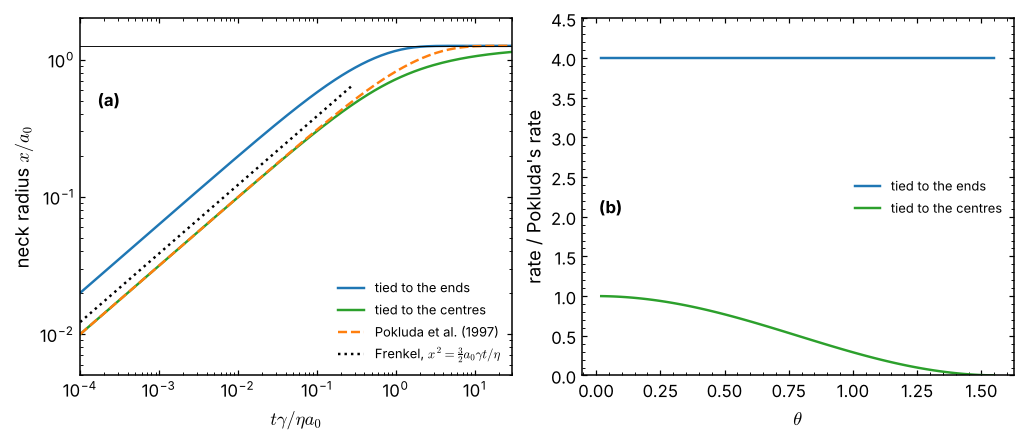

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
t = np.logspace(-4, 1.5, 200)
neck = sp.lambdify(th, (a * sp.sin(th)).subs(a0, 1))
curves = {}
for tie, color in (("ends", "C0"), ("centres", "C2")):
    f = sp.lambdify(th, rates[tie].subs({a0: 1, gam: 1, eta: 1}))
    sol = solve_ivp(lambda tt, y: [f(y[0])], (0, t[-1]), [1e-4], t_eval=t, rtol=1e-9, atol=1e-12, method="LSODA")
    curves[tie] = neck(sol.y[0])
    ax1.loglog(t, curves[tie], color=color, label=f"tied to the {tie}")
f = sp.lambdify(th, pokluda.subs({a0: 1, gam: 1, eta: 1}))
sol = solve_ivp(lambda tt, y: [f(y[0])], (0, t[-1]), [1e-4], t_eval=t, rtol=1e-9, atol=1e-12, method="LSODA")
ax1.loglog(t, neck(sol.y[0]), "C1--", label="Pokluda et al. (1997)")
ax1.loglog(t[t < 0.3], np.sqrt(1.5 * t[t < 0.3]), "k:", label=r"Frenkel, $x^2 = \frac{3}{2}a_0\gamma t/\eta$")
ax1.axhline(2 ** (1 / 3), color="k", lw=0.6)
ax1.set_xlabel(r"$t\gamma/\eta a_0$"); ax1.set_ylabel("neck radius $x/a_0$")
ax1.set_xlim(1e-4, 30); ax1.set_ylim(5e-3, 2)
ax1.legend(loc="lower right", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.04, y=0.8)

thetas = np.linspace(0.02, 1.55, 100)
for tie, color in (("ends", "C0"), ("centres", "C2")):
    ax2.plot(thetas, [float((rates[tie] / pokluda).subs({th: s, a0: 1, gam: 1, eta: 1})) for s in thetas], color=color, label=f"tied to the {tie}")
ax2.set_xlabel(r"$\theta$"); ax2.set_ylabel("rate / Pokluda's rate"); ax2.set_ylim(0, 4.5)
ax2.legend(loc="center right", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.04, y=0.5)
plt.show()

**Figure S8.1.** Frenkel's model for two spheres. **(a)** Neck radius against time
for the two ties, Pokluda's equation and Frenkel's early law. All end at the
radius $2^{1/3}a_0$ of the final sphere. **(b)** The rate $d\theta/dt$ divided by
Pokluda's: exactly 4 for the tie to the far ends.

For spheres there is no exact solution to check against. Exact work on the early
stage (Eggers, Lister and Stone, 1999) shows that, as for cylinders, the neck first
grows almost linearly, $x \simeq (\gamma t/\pi\eta)\ln(\ldots)$, so the square-root law is
again an artefact of a flow that does not fill the neck.

## Exercise 2. The last stage

(a) For $r = R_0(1 + \varepsilon\cos2\varphi) + O(\varepsilon^2)$ the area is fixed if the mean
radius is $R_0(1 - \varepsilon^2/4)$. The perimeter
$\int(r^2 + r'^2)^{1/2}d\varphi = 2\pi R_0[(1 - \varepsilon^2/4) + n^2\varepsilon^2/4]$ with $n = 2$, so the
excess is $\tfrac32\pi R_0\varepsilon^2$ and $A = \tfrac32\pi\gamma R_0\varepsilon^2$.

(b), (c) The stream function $\psi = (\alpha r^2 + \beta r^4)\sin2\varphi$ gives an
incompressible flow; both terms are solutions of the biharmonic equation. The
boundary moves with $v_r(R) = R\dot\varepsilon\cos2\varphi$, which fixes $\alpha$ in terms of
$\beta$ and $\dot\varepsilon$. The cell computes $\Phi$, minimises over $\beta$, and solves
$\partial\Phi/\partial\dot\varepsilon = -\partial A/\partial\varepsilon$.

In [4]:
r, phi, R, alpha, beta, eps, epsd = sp.symbols("r varphi R alpha beta epsilon epsilondot", real=True)
psi = (alpha * r**2 + beta * r**4) * sp.sin(2 * phi)
ur, uphi = sp.diff(psi, phi) / r, -sp.diff(psi, r)
err = sp.diff(ur, r)
epp = ur / r + sp.diff(uphi, phi) / r
erp = (sp.diff(ur, phi) / r + sp.diff(uphi, r) - uphi / r) / 2
print("incompressible:", sp.simplify(err + epp) == 0,
      "   biharmonic:", sp.simplify(sp.diff(r * sp.diff(sp.diff(r * sp.diff(psi, r), r) / r + sp.diff(psi, phi, 2) / r**2, r), r) / r
                                    + sp.diff(sp.diff(r * sp.diff(psi, r), r) / r + sp.diff(psi, phi, 2) / r**2, phi, 2) / r**2) == 0)
Phi = sp.integrate(sp.integrate(eta * (err**2 + epp**2 + 2 * erp**2) * r, (phi, 0, 2 * sp.pi)), (r, 0, R))   # half of 2 eta e:e
alpha_c = sp.solve(sp.Eq(sp.simplify(ur.subs(r, R) / sp.cos(2 * phi)), R * epsd), alpha)[0]
Phi = sp.simplify(Phi.subs(alpha, alpha_c))
A_eps = sp.Rational(3, 2) * sp.pi * gam * R * eps**2
for name, Phi_trial in (("uniform extension, beta = 0", Phi.subs(beta, 0)),
                        ("optimal beta", Phi.subs(beta, sp.solve(sp.diff(Phi, beta), beta)[0]))):
    rate = sp.solve(sp.Eq(sp.diff(Phi_trial, epsd), -sp.diff(A_eps, eps)), epsd)[0]
    print(f"{name:28s}  Phi = {sp.simplify(Phi_trial)}    epsilondot = {sp.simplify(rate)}")
beta_opt = sp.solve(sp.diff(Phi, beta), beta)[0]
print("shear stress at r = R for the optimal beta:", sp.simplify(erp.subs({alpha: alpha_c, beta: beta_opt}).subs(r, R)))
print("Hopper's late rate for R = R_f: 1/tau_H = gamma/(eta R_f)")

incompressible: True    biharmonic: True
uniform extension, beta = 0   Phi = 2*pi*R**2*epsilondot**2*eta    epsilondot = -3*epsilon*gamma/(4*R*eta)
optimal beta                  Phi = 3*pi*R**2*epsilondot**2*eta/2    epsilondot = -epsilon*gamma/(R*eta)


shear stress at r = R for the optimal beta: 0
Hopper's late rate for R = R_f: 1/tau_H = gamma/(eta R_f)


The uniform extension gives $\dot\varepsilon = -3\gamma\varepsilon/4\eta R$; with the optimal
$r^4$ term the dissipation falls from $2\pi\eta R^2\dot\varepsilon^2$ to
$\tfrac32\pi\eta R^2\dot\varepsilon^2$ and the rate becomes $\gamma/\eta R$. This is exactly the
late-time rate of Hopper's solution, $1/\tau_H$ with $\tau_H = \eta R_f/\gamma$, and the
ratio $4/3$ is the one found for the potential flow in Figure 8.3(b): near the end
the potential flow *is* the uniform extension.

The optimal flow has no shear stress at the surface, although nothing imposed it.
Minimising the dissipation at a fixed normal velocity of the boundary leaves the
tangential velocity free, and the condition that makes the dissipation stationary
with respect to it is that the shear stress vanish. This is the natural boundary
condition of a free surface, produced by the minimum principle.

## Exercise 3. The early neck

Write $m = 1 - \varepsilon$. On the interval $m^2 < s < 1$ we have $s \simeq 1$, so
$s\,(1 + s)^{1/2} \simeq \sqrt2$, and with $u = 1 - s$,

$$ \frac{t}{\tau} \simeq \frac{\pi}{4}\int_0^{1 - m^2}\frac{du}{\tfrac12\ln(16/u)} \simeq \frac{\pi}{2}\,\frac{U}{\ln(16/U)} , \qquad U = 1 - m^2 \simeq 2\varepsilon , $$

where the last step keeps the leading term (the logarithm varies slowly). The neck
is $x = \sqrt2\,\varepsilon/(1 + m^2)^{1/2} \simeq \varepsilon\,a_0$, so

$$ \frac{t}{\tau} \simeq \frac{\pi\,x/a_0}{\ln(8a_0/x)} , \qquad x \simeq \frac{\gamma t}{\pi\eta}\,\ln\frac{8a_0}{x} . $$

The 8 comes from the 16 of the elliptic integral and the factor 2 in
$1 - m^2 \simeq 2(1 - m)$; physically, it fixes where the logarithm is cut off, at
a distance of order $a_0$, the size of the drop. The cell compares the formula
with the exact time.

In [5]:
print("    x/a0       exact t     pi x / ln(8/x)    ratio")
for eps_ in (1e-2, 1e-3, 1e-4, 1e-5, 1e-6):
    m = 1 - eps_
    x = float(on.hopper_neck(m))
    approx = math.pi * x / math.log(8 / x)
    print(f"  {x:9.2e}   {on.hopper_time(m):9.3e}     {approx:9.3e}       {on.hopper_time(m) / approx:.4f}")

    x/a0       exact t     pi x / ln(8/x)    ratio
   1.01e-02   4.170e-03     4.727e-03       0.8821
   1.00e-03   3.175e-04     3.498e-04       0.9076
   1.00e-04   2.571e-05     2.783e-05       0.9240
   1.00e-05   2.162e-06     2.311e-06       0.9354
   1.00e-06   1.865e-07     1.976e-07       0.9438


The ratio tends to 1 slowly, as the next term of the expansion is smaller only by
a factor $1/\ln(8a_0/x)$.

*Why almost linear.* The driving force on the neck is constant, $-\gamma\,dP/dx = 4\gamma$,
because two notches of the surface disappear as the neck widens. The exact friction
is $\zeta_x \simeq 4\pi\eta/\ln(8a_0/x)$: the flow that fills the neck is concentrated in
a region of size $x$, and in two dimensions such a flow decays only logarithmically
away from it, up to the size of the drop. Hence $\dot x \simeq (\gamma/\pi\eta)\ln(8a_0/x)$,
a speed that varies only logarithmically. A trial with a uniform rate of strain
gives a friction that vanishes as a power of $x$ ($2\pi\eta x^2/a_0^2$ for Frenkel's
cylinders), and with a constant force this produces a power law $x \propto t^{1/3}$.

## Exercise 4. Sintering in practice

(a) From the exact solution, the neck reaches half the radius at $t = 0.462\,\tau$
and 90 % of the shortening is reached at $t = 4.02\,\tau$. (b) With a velocity of
order $a_0/\tau$, the Reynolds number is $\mathrm{Re} = \rho a_0^2/\eta\tau = \rho a_0\gamma/\eta^2$.

In [6]:
t_half = on.hopper_time(brentq(lambda m: on.hopper_neck(m) - 0.5, 0, 1))
t_90 = on.hopper_time(brentq(lambda m: (2 - on.hopper_length(m)) / (2 - math.sqrt(2)) - 0.9, 1e-12, 1 - 1e-12))
cases = [("polymer melt, 0.2 mm grains", 1.0e3, 0.03, 0.2e-3, 1000.0),
         ("glass at its softening point, 50 um grains", 10**6.6, 0.3, 50e-6, 2500.0)]
print(f"exact: neck = a0/2 at {t_half:.3f} tau,  90 % of the shortening at {t_90:.3f} tau\n")
for name, viscosity, tension, radius, density in cases:
    tau = viscosity * radius / tension
    print(f"{name}:  tau = {tau:.1f} s;  neck a0/2 after {t_half * tau:.1f} s;  90 % after {t_90 * tau:.0f} s;"
          f"  Re = {density * radius * tension / viscosity**2:.1e}")
print(f"\nwater-like density, a0 = 1 mm, gamma = 0.03 N/m: Re < 0.1 needs eta > {math.sqrt(1000 * 1e-3 * 0.03 / 0.1):.2f} Pa s")

# (c) Frenkel's model for cylinders, tied to the far ends (Section 8.2)
def geometry(theta):
    radius = math.sqrt(math.pi / (math.pi - theta + math.sin(theta) * math.cos(theta)))
    return radius * math.sin(theta), radius * (1 + math.cos(theta)), 4 * radius * (math.pi - theta)
def d(f, s, h=1e-6):
    return (f(s + h) - f(s - h)) / (2 * h)
def rate(theta):
    e = d(lambda s: geometry(s)[1], theta) / geometry(theta)[1]
    return -d(lambda s: geometry(s)[2], theta) / (8 * math.pi * e**2)
tt = np.logspace(-6, 1, 400)
sol = solve_ivp(lambda t, y: [rate(y[0])], (0, tt[-1]), [1e-3], t_eval=tt, rtol=1e-9, atol=1e-12, method="LSODA")
g = np.array([geometry(s) for s in sol.y[0]])
print(f"\nFrenkel's model: neck a0/2 at {np.interp(0.5, g[:, 0], tt):.3f} tau (exact {t_half:.3f});"
      f"  90 % of the shortening at {np.interp(0.9, (2 - g[:, 1]) / (2 - math.sqrt(2)), tt):.3f} tau (exact {t_90:.3f})")

exact: neck = a0/2 at 0.462 tau,  90 % of the shortening at 4.017 tau

polymer melt, 0.2 mm grains:  tau = 6.7 s;  neck a0/2 after 3.1 s;  90 % after 27 s;  Re = 6.0e-09
glass at its softening point, 50 um grains:  tau = 663.5 s;  neck a0/2 after 306.5 s;  90 % after 2665 s;  Re = 2.4e-15

water-like density, a0 = 1 mm, gamma = 0.03 N/m: Re < 0.1 needs eta > 0.55 Pa s

Frenkel's model: neck a0/2 at 0.050 tau (exact 0.462);  90 % of the shortening at 1.532 tau (exact 4.017)


Inertia is negligible by many orders of magnitude for melts and glasses; for a
liquid of water-like density and millimetre drops the viscous description needs a
viscosity above about half a pascal second, and for water itself the coalescence
of millimetre drops is governed by inertia, not by viscosity.

Frenkel's model predicts the neck of half the radius about nine times too early,
and 90 % of the shortening two and a half times too early. Since all times scale with
$\eta/\gamma$, fitting the model to measured necks would return a viscosity too large
by a similar factor.